In [217]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from scipy.stats import pearsonr

In [218]:
end_date = pd.Timestamp('2022-03-31')

In [219]:
raw_df = pd.read_csv("df_india.csv")


raw_df["date"] = pd.to_datetime(raw_df["date"])
raw_df = raw_df.sort_values("date").reset_index(drop=True)


In [220]:
df = raw_df[
    (raw_df["date"] <= end_date)
].copy()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 792 entries, 0 to 791
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   date                       792 non-null    datetime64[us]
 1   total_cases                792 non-null    float64       
 2   new_cases                  792 non-null    float64       
 3   new_cases_smoothed         792 non-null    float64       
 4   total_deaths               792 non-null    float64       
 5   new_deaths                 792 non-null    float64       
 6   new_deaths_smoothed        792 non-null    float64       
 7   stringency_index           792 non-null    float64       
 8   positive_rate              792 non-null    float64       
 9   new_tests_smoothed         792 non-null    float64       
 10  people_fully_vaccinated    792 non-null    float64       
 11  new_vaccinations_smoothed  792 non-null    float64       
 12  reproduction_rate  

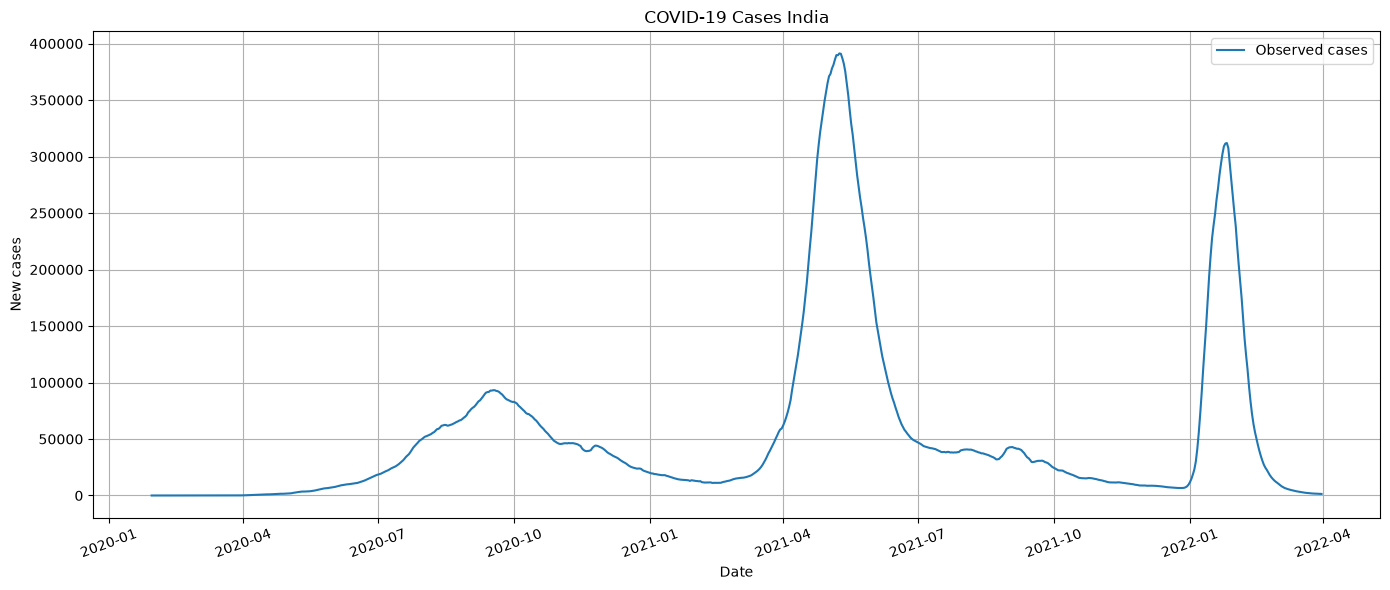

In [221]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["new_cases_smoothed"],
    label="Observed cases"
)

plt.xlabel("Date")
plt.ylabel("New cases")
plt.title(f"COVID-19 Cases India")

plt.grid(True)
plt.legend()

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [222]:
# lag + seasonal features
df["lag1"] = df["new_cases_smoothed"].shift(1)
df["lag2"] = df["new_cases_smoothed"].shift(2)
df["lag3"] = df["new_cases_smoothed"].shift(3)
df["lag7"] = df["new_cases_smoothed"].shift(7)
df["lag14"] = df["new_cases_smoothed"].shift(14)
df["rolling14"] = (df["new_cases_smoothed"].shift(1).rolling(14).mean())
df["rolling28"] = (df["new_cases_smoothed"].shift(1).rolling(28).mean())

features = ["lag1", "lag2", "lag3", "lag7", "lag14", "rolling14", "rolling28"]

In [223]:
train_end_date = pd.Timestamp('2021-09-30')

In [240]:
# fit the data to model and evaluate training set
train = df[df["date"] <= train_end_date].dropna(subset=features)

# hyperparameters for tuning
param_grid = {
    'n_estimators': [50, 100, 200, 300, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5, 6],
    'reg_alpha': [0, 0.01, 0.1, 0.5, 1.0],      # L1 regularization
    'reg_lambda': [0.0, 0.01, 0.1, 0.5, 1.0]    # L2 regularization
}

# use TimeSeriesSplit to avoid data leakage (looking into the future) during cross-validation
tscv = TimeSeriesSplit(n_splits=3)

base_model = XGBRegressor(booster='gbtree', random_state=42)

# grid search for best parameter selection
random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_grid,
    n_iter=50,         
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    verbose=1,
    random_state=42,       # Ensure reproducibility
    n_jobs=-1
)

random_search.fit(train[features], train["new_cases_smoothed"])

print(f"Best parameters found: {random_search.best_params_}")

model = random_search.best_estimator_

# model = XGBRegressor(
#     booster='gblinear',
#     n_estimators=200, 
#     learning_rate=0.05, 
#     random_state=42
# )
# model.fit(
#     train[features],
#     train["new_cases_smoothed"]
# )

def evaluate(y_true, y_pred, name="set"):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true, y_pred = y_true[ok], y_pred[ok]

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    corr = pearsonr(y_true, y_pred)[0]

    print(
        f"{name:26s} "
        f"RMSE={rmse:7.1f} "
        f"MAE={mae:7.1f} "
        f"R2={r2:5.2f} "
        f"corr={corr:.2f}"
    )

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best parameters found: {'reg_lambda': 0.01, 'reg_alpha': 1.0, 'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.01}


In [241]:
# in-sample fit
cases = df["new_cases_smoothed"].values
fit = np.full(len(df), np.nan)
have_features = df[features].notna().all(axis=1).values
# Ensure in-sample predictions also don't drop below zero
fit[have_features] = np.maximum(0, model.predict(df.loc[have_features, features]))

In [242]:
# Rolling 2-week recursive forecasting
forecast_2wk = np.full(len(df), np.nan)
persist_fc = np.full(len(df), np.nan)
seasonal_fc = np.full(len(df), np.nan)

# train_end_idx = first index of the test period
train_end_idx = df.index[df["date"] <= train_end_date][-1] + 1

# New forecast origin every 14 days
for origin in range(train_end_idx, len(df) - 13, 14):
    hist = cases.copy()
    
    for step in range(14):
        w = origin + step
        x = pd.DataFrame([[
            hist[w - 1], hist[w - 2], hist[w - 3], hist[w - 7], hist[w - 14], 
            hist[w-14:w].mean(), hist[w-28:w].mean()
        ]], columns=features)
        
        # Apply zero-floor constraint to stop negative spiraling
        pred = model.predict(x)[0]
        hist[w] = max(0, pred)

    forecast_2wk[origin:origin + 14] = hist[origin:origin + 14]
    persist_fc[origin:origin + 14] = cases[origin - 1]
    seasonal_fc[origin:origin + 14] = cases[origin - 365:origin - 365 + 14]

In [243]:
# Rolling 3-week recursive forecasting
forecast_3wk = np.full(len(df), np.nan)

for origin in range(train_end_idx, len(df) - 20, 21):
        hist = cases.copy()
        for step in range(21):
            w = origin + step
            x = pd.DataFrame([[
                hist[w-1], hist[w-2], hist[w-3], hist[w-7], hist[w-14], 
                hist[w-14:w].mean(), hist[w-21:w].mean()
            ]], columns=features)
            
            hist[w] = max(0, model.predict(x)[0])

        forecast_3wk[origin:origin + 21] = hist[origin:origin + 21]

In [244]:
# Full test-period recursive forecast
fc_whole = np.full(len(df), np.nan)
hist = cases.copy()

for w in range(train_end_idx, len(df)):
    x = pd.DataFrame([[
        hist[w - 1], hist[w - 2], hist[w - 3], hist[w - 7], hist[w-14],
        hist[w-14:w].mean(), hist[w-28:w].mean()
    ]], columns=features)

    pred = model.predict(x)[0]
    hist[w] = max(0, pred)

fc_whole[train_end_idx:] = hist[train_end_idx:]

In [245]:
# performance evaluation
test = slice(train_end_idx, len(df))

evaluate(cases[:train_end_idx], fit[:train_end_idx], "Train (in-sample fit)")
evaluate(cases[test], forecast_2wk[test], "Test 2-wk rolling forecast")
evaluate(cases[test], forecast_3wk[test], "Test 3-wk rolling forecast")
evaluate(cases[test], fc_whole[test], "Test whole-period forecast")
evaluate(cases[test], persist_fc[test], "Baseline persistence")
evaluate(cases[test], seasonal_fc[test], "Baseline seasonal")

Train (in-sample fit)      RMSE=  606.1 MAE=  423.5 R2= 1.00 corr=1.00
Test 2-wk rolling forecast RMSE=41436.4 MAE=18474.4 R2= 0.76 corr=0.87
Test 3-wk rolling forecast RMSE=66774.4 MAE=33016.7 R2= 0.41 corr=0.70
Test whole-period forecast RMSE=88479.4 MAE=47381.7 R2=-0.10 corr=0.05
Baseline persistence       RMSE=53918.5 MAE=24000.5 R2= 0.59 corr=0.79
Baseline seasonal          RMSE=96525.5 MAE=61350.0 R2=-0.30 corr=-0.44


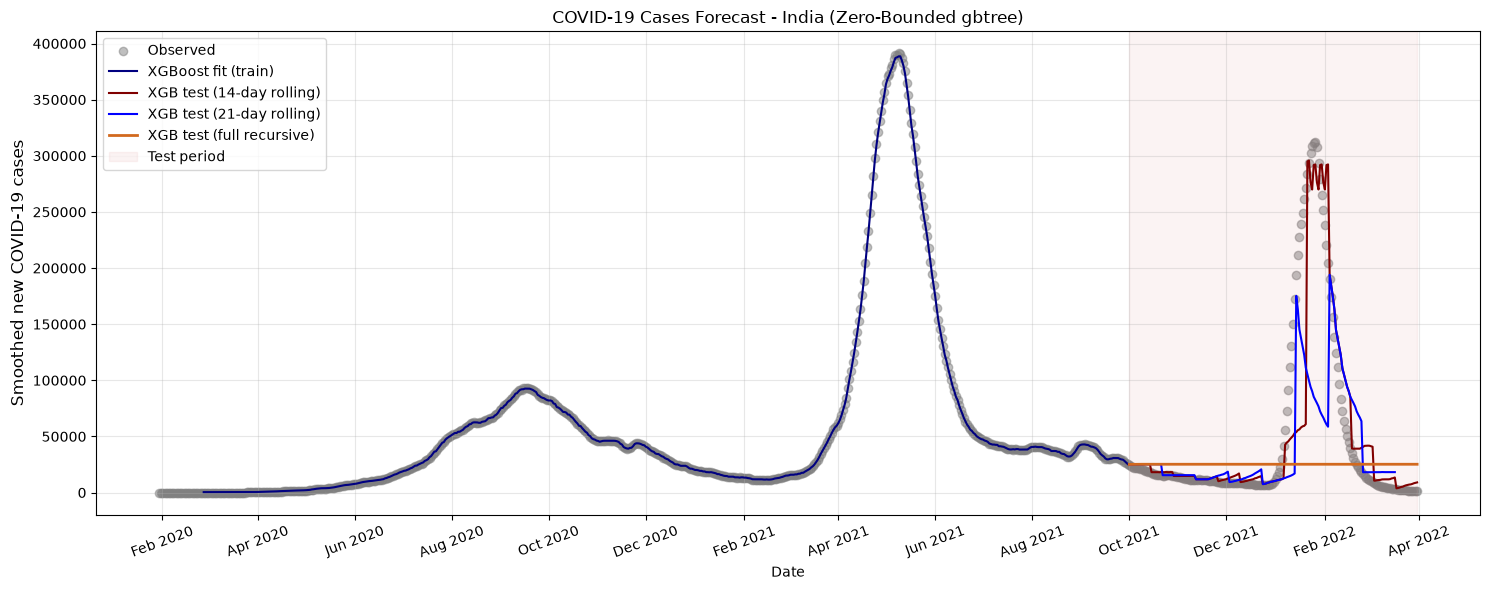

In [246]:
# Figures
def style():
    plt.title("COVID-19 Cases Forecast - India (Zero-Bounded gbtree)")
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.xticks(rotation=20)
    plt.xlabel("Date")
    plt.ylabel("Smoothed new COVID-19 cases", fontsize=12)
    plt.legend()

plt.figure(figsize=(15, 6))
plt.grid(True, alpha=0.3)
plt.scatter(df["date"], cases, color="grey", alpha=0.5, label="Observed")

plt.plot(df["date"].iloc[:train_end_idx], fit[:train_end_idx], color="navy", lw=1.5, label="XGBoost fit (train)")
plt.plot(df["date"], forecast_2wk, color="maroon", lw=1.5, label="XGB test (14-day rolling)")
plt.plot(df["date"], forecast_3wk, color="blue", lw=1.5, label="XGB test (21-day rolling)")
plt.plot(df["date"].iloc[train_end_idx:], fc_whole[train_end_idx:], color="chocolate", lw=2, label="XGB test (full recursive)")

plt.axvspan(df["date"].iloc[train_end_idx], df["date"].iloc[-1], color="indianred", alpha=0.07, label="Test period")

style()
plt.tight_layout()
plt.show()